# Environment Setup & Dataset Exploration

## Import libraries and configure the GPU

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## Load dataset files

In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
  for filename in filenames:
    print(os.path.join(dirname, filename))

/kaggle/input/datasets/gowrishankarp/newspaper-text-summarization-cnn-dailymail/cnn_dailymail/test.csv
/kaggle/input/datasets/gowrishankarp/newspaper-text-summarization-cnn-dailymail/cnn_dailymail/train.csv
/kaggle/input/datasets/gowrishankarp/newspaper-text-summarization-cnn-dailymail/cnn_dailymail/validation.csv


In [3]:
DATA_PATH = "/kaggle/input/datasets/gowrishankarp/newspaper-text-summarization-cnn-dailymail/cnn_dailymail/"

train_df = pd.read_csv(DATA_PATH + "train.csv")
val_df = pd.read_csv(DATA_PATH + "validation.csv")
test_df = pd.read_csv(DATA_PATH + "test.csv")

print("Training Dataset:", train_df.shape)
print("Validation Dataset:", val_df.shape)
print("Testing Dataset:", test_df.shape)

display(train_df.head())

Training Dataset: (287113, 3)
Validation Dataset: (13368, 3)
Testing Dataset: (11490, 3)


,id,article,highlights
0,0001d1afc246a7964130f43ae940af6bc6c57f01,By . Associated Press . PUBLISHED: . 14:11 EST...,"Bishop John Folda, of North Dakota, is taking ..."
1,0002095e55fcbd3a2f366d9bf92a95433dc305ef,(CNN) -- Ralph Mata was an internal affairs li...,Criminal complaint: Cop used his role to help ...
2,00027e965c8264c35cc1bc55556db388da82b07f,A drunk driver who killed a young woman in a h...,"Craig Eccleston-Todd, 27, had drunk at least t..."
3,0002c17436637c4fe1837c935c04de47adb18e9a,(CNN) -- With a breezy sweep of his pen Presid...,Nina dos Santos says Europe must be ready to a...
4,0003ad6ef0c37534f80b55b4235108024b407f0b,Fleetwood are the only team still to have a 10...,Fleetwood top of League One after 2-0 win at S...


## Basic Dataset Exploration

In [4]:
print("Column Names:")
print(train_df.columns.tolist())

print("\nDataset Information:")
train_df.info()

print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nDuplicate Article-Summary Pairs:")
print(train_df.duplicated(
    subset=["article", "highlights"]
).sum())

Column Names:
['id', 'article', 'highlights']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 287113 entries, 0 to 287112
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id          287113 non-null  object
 1   article     287113 non-null  object
 2   highlights  287113 non-null  object
dtypes: object(3)
memory usage: 6.6+ MB

Missing Values:
id            0
article       0
highlights    0
dtype: int64

Duplicate Article-Summary Pairs:
3098


## Explore Random Samples

In [5]:
samples = train_df.sample(n=3, random_state=SEED)

for i, (_, row) in enumerate(samples.iterrows(), 1):
    print(f"\n{'='*20} SAMPLE {i} {'='*20}")

    print("\nARTICLE:")
    print(str(row["article"])[:1500])

    print("\nSUMMARY:")
    print(row["highlights"])


==================== SAMPLE 1 ====================

ARTICLE:
By . Mia De Graaf . Britons flocked to beaches across the southern coast yesterday as millions look set to bask in glorious sunshine today. Temperatures soared to 17C in Brighton and Dorset, with people starting their long weekend in deck chairs by the sea. Figures from Asda suggest the unexpected sunshine has also inspired a wave of impromptu barbecues, with sales of sausages and equipment expected to triple those in April. Sun's out: Brighton beach was packed with Britons enjoying the unexpected sunshine to start the long weekend as temperatures hit 17C across the south coast . Although frost is set to hit the south tonight - with temperatures dropping to 1C - Britons stocking up for a barbecue will be in luck tomorrow, with forecasters predicting dry and sunny weather across southern England, southern Wales and the south Midlands. In Weymouth, Dorset, the sun came out in time for the town's annual kite festival, held on t

## Analyze Article and Summary Lengths

In [6]:
eda_df = train_df.sample(
    n=min(5000, len(train_df)),
    random_state=SEED
).copy()

eda_df["article_length"] = (
    eda_df["article"].fillna("").str.split().str.len()
)

eda_df["summary_length"] = (
    eda_df["highlights"].fillna("").str.split().str.len()
)

print("Article Length Statistics:")
print(eda_df["article_length"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
))

print("\nSummary Length Statistics:")
print(eda_df["summary_length"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
))

Article Length Statistics:
count    5000.000000
mean      698.094600
std       343.526824
min        21.000000
50%       636.000000
90%      1179.100000
95%      1395.000000
99%      1702.010000
max      1955.000000
Name: article_length, dtype: float64

Summary Length Statistics:
count    5000.000000
mean       51.899600
std        20.763645
min         9.000000
50%        49.000000
90%        78.000000
95%        92.000000
99%       122.000000
max       320.000000
Name: summary_length, dtype: float64


## Visualize Length Distributions

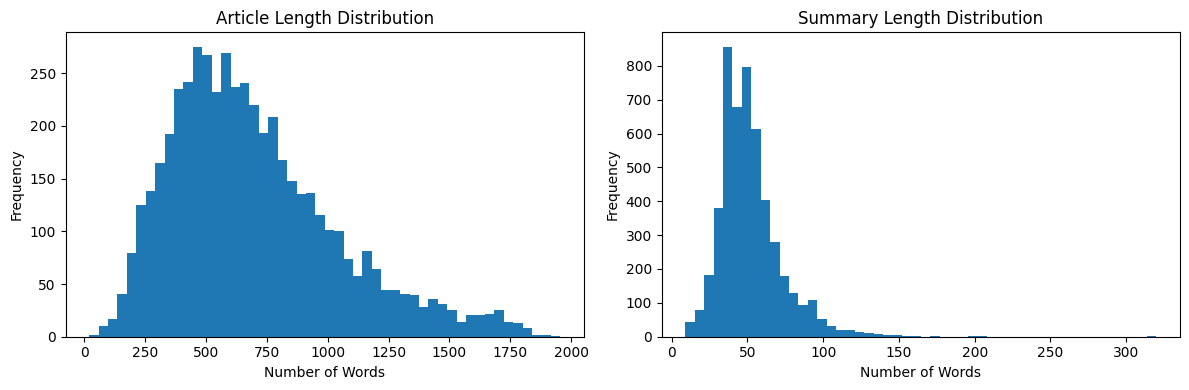

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(eda_df["article_length"], bins=50)
axes[0].set_title("Article Length Distribution")
axes[0].set_xlabel("Number of Words")
axes[0].set_ylabel("Frequency")

axes[1].hist(eda_df["summary_length"], bins=50)
axes[1].set_title("Summary Length Distribution")
axes[1].set_xlabel("Number of Words")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Data Preprocessing

## Text Cleaning

In [8]:
import re
import html

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def preprocess_dataframe(df):
    df = df.dropna(
        subset=["article", "highlights"]
    ).copy()

    df["article"] = df["article"].apply(clean_text)
    df["highlights"] = df["highlights"].apply(clean_text)

    df = df[
        (df["article"].str.len() > 0) &
        (df["highlights"].str.len() > 0)
    ]

    return df.reset_index(drop=True)

train_df = preprocess_dataframe(train_df)
val_df = preprocess_dataframe(val_df)
test_df = preprocess_dataframe(test_df)

display(train_df[["article", "highlights"]].head())

,article,highlights
0,By . Associated Press . PUBLISHED: . 14:11 EST...,"Bishop John Folda, of North Dakota, is taking ..."
1,(CNN) -- Ralph Mata was an internal affairs li...,Criminal complaint: Cop used his role to help ...
2,A drunk driver who killed a young woman in a h...,"Craig Eccleston-Todd, 27, had drunk at least t..."
3,(CNN) -- With a breezy sweep of his pen Presid...,Nina dos Santos says Europe must be ready to a...
4,Fleetwood are the only team still to have a 10...,Fleetwood top of League One after 2-0 win at S...


## Remove Duplicates and Prevent Leakage

In [9]:
before = len(train_df)

train_df = train_df.drop_duplicates(
    subset=["article", "highlights"]
).reset_index(drop=True)

print("Duplicates Removed:", before - len(train_df))

heldout_articles = (
    set(val_df["article"]) |
    set(test_df["article"])
)

before = len(train_df)

train_df = train_df[
    ~train_df["article"].isin(heldout_articles)
].reset_index(drop=True)

print("Overlapping Articles Removed:",
      before - len(train_df))

print("Remaining Training Samples:", len(train_df))

Duplicates Removed: 3100
Overlapping Articles Removed: 1
Remaining Training Samples: 284012


## Create Training Subsets

In [10]:
TRAIN_SAMPLES = 30000
VAL_SAMPLES = 2000
TEST_SAMPLES = 2000

train_data = train_df.sample(
    n=min(TRAIN_SAMPLES, len(train_df)),
    random_state=SEED
).reset_index(drop=True)

val_data = val_df.sample(
    n=min(VAL_SAMPLES, len(val_df)),
    random_state=SEED
).reset_index(drop=True)

test_data = test_df.sample(
    n=min(TEST_SAMPLES, len(test_df)),
    random_state=SEED
).reset_index(drop=True)

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Testing:", test_data.shape)

Training: (30000, 3)
Validation: (2000, 3)
Testing: (2000, 3)


# Subword Tokenization

## Initialize the BPE Tokenizer

In [11]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

VOCAB_SIZE = 16000

SPECIAL_TOKENS = [
    "<pad>",
    "<unk>",
    "<bos>",
    "<eos>"
]

tokenizer = Tokenizer(
    models.BPE(unk_token="<unk>")
)

tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)

tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=SPECIAL_TOKENS,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
)

## Train the Tokenizer

In [12]:
def text_iterator(df):
    for row in df.itertuples(index=False):
        yield row.article
        yield row.highlights

tokenizer.train_from_iterator(
    text_iterator(train_data),
    trainer=trainer,
    length=len(train_data) * 2
)

print("Vocabulary Size:", tokenizer.get_vocab_size())




Vocabulary Size: 16000


## Get Special Token IDs

In [13]:
PAD_ID = tokenizer.token_to_id("<pad>")
UNK_ID = tokenizer.token_to_id("<unk>")
BOS_ID = tokenizer.token_to_id("<bos>")
EOS_ID = tokenizer.token_to_id("<eos>")

print("PAD ID:", PAD_ID)
print("UNK ID:", UNK_ID)
print("BOS ID:", BOS_ID)
print("EOS ID:", EOS_ID)

PAD ID: 0
UNK ID: 1
BOS ID: 2
EOS ID: 3


## Test Tokenization

In [14]:
sample_text = "Artificial Intelligence is transforming the world."

encoded = tokenizer.encode(
    sample_text,
    add_special_tokens=False
)

print("Original Text:", sample_text)
print("Tokens:", encoded.tokens)
print("Token IDs:", encoded.ids)

decoded = tokenizer.decode(encoded.ids)

print("Decoded Text:", decoded)

Original Text: Artificial Intelligence is transforming the world.
Tokens: ['Ar', 't', 'ific', 'ial', 'ĠIntelligence', 'Ġis', 'Ġtransform', 'ing', 'Ġthe', 'Ġworld', '.']
Token IDs: [7307, 87, 1334, 502, 11853, 342, 6376, 280, 266, 922, 17]
Decoded Text: Artificial Intelligence is transforming the world.


## Save the Tokenizer

In [15]:
TOKENIZER_PATH = "/kaggle/working/cnn_dm_bpe_tokenizer.json"

tokenizer.save(TOKENIZER_PATH)

print("Tokenizer saved to:", TOKENIZER_PATH)

Tokenizer saved to: /kaggle/working/cnn_dm_bpe_tokenizer.json


# Sequence Encoding

## Define Sequence Lengths

In [16]:
MAX_ARTICLE_LEN = 384
MAX_SUMMARY_LEN = 128

print("Maximum Article Length:", MAX_ARTICLE_LEN)
print("Maximum Summary Length:", MAX_SUMMARY_LEN)

Maximum Article Length: 384
Maximum Summary Length: 128


## Implement Encoding Functions

In [17]:
def encode_article(text):
    tokens = tokenizer.encode(
        text,
        add_special_tokens=False
    ).ids

    tokens = tokens[:MAX_ARTICLE_LEN - 2]

    return [BOS_ID] + tokens + [EOS_ID]


def encode_summary(text):
    tokens = tokenizer.encode(
        text,
        add_special_tokens=False
    ).ids

    tokens = tokens[:MAX_SUMMARY_LEN - 2]

    return [BOS_ID] + tokens + [EOS_ID]

## Test Sequence Encoding

In [18]:
sample_article = train_data.iloc[0]["article"]
sample_summary = train_data.iloc[0]["highlights"]

article_ids = encode_article(sample_article)
summary_ids = encode_summary(sample_summary)

print("Article Token Count:", len(article_ids))
print("Summary Token Count:", len(summary_ids))

print("\nArticle First 10 IDs:", article_ids[:10])
print("Summary First 10 IDs:", summary_ids[:10])

print("\nArticle BOS/EOS:",
      article_ids[0], article_ids[-1])

print("Summary BOS/EOS:",
      summary_ids[0], summary_ids[-1])

assert len(article_ids) <= MAX_ARTICLE_LEN
assert len(summary_ids) <= MAX_SUMMARY_LEN

assert article_ids[0] == BOS_ID
assert article_ids[-1] == EOS_ID

assert summary_ids[0] == BOS_ID
assert summary_ids[-1] == EOS_ID

print("\nAll checks passed!")

Article Token Count: 384
Summary Token Count: 118

Article First 10 IDs: [2, 1175, 298, 4983, 15042, 298, 630, 406, 812, 646]
Summary First 10 IDs: [2, 14538, 3424, 401, 6396, 280, 13966, 1872, 15, 2178]

Article BOS/EOS: 2 3
Summary BOS/EOS: 2 3

All checks passed!


## Analyze Truncation

In [19]:
sample_df = train_data.sample(
    n=min(1000, len(train_data)),
    random_state=SEED
)

article_lengths = [
    len(tokenizer.encode(text).ids)
    for text in sample_df["article"]
]

summary_lengths = [
    len(tokenizer.encode(text).ids)
    for text in sample_df["highlights"]
]

article_truncated = np.mean(
    np.array(article_lengths) > MAX_ARTICLE_LEN - 2
) * 100

summary_truncated = np.mean(
    np.array(summary_lengths) > MAX_SUMMARY_LEN - 2
) * 100

print(f"Articles Truncated: {article_truncated:.2f}%")
print(f"Summaries Truncated: {summary_truncated:.2f}%")

Articles Truncated: 91.80%
Summaries Truncated: 2.80%


# Custom Dataset & DataLoader

## Update Maximum Article Length

In [20]:
MAX_ARTICLE_LEN = 512
MAX_SUMMARY_LEN = 128

BATCH_SIZE = 8

print("Article Length:", MAX_ARTICLE_LEN)
print("Summary Length:", MAX_SUMMARY_LEN)
print("Batch Size:", BATCH_SIZE)

Article Length: 512
Summary Length: 128
Batch Size: 8


## Implement Custom PyTorch Dataset

In [21]:
from torch.utils.data import Dataset, DataLoader

class NewsSummarizationDataset(Dataset):

    def __init__(self, dataframe):
        self.articles = dataframe["article"].tolist()
        self.summaries = dataframe["highlights"].tolist()

    def __len__(self):
        return len(self.articles)

    def __getitem__(self, idx):
        article = self.articles[idx]
        summary = self.summaries[idx]

        article_ids = encode_article(article)
        summary_ids = encode_summary(summary)

        return {
            "article_ids": torch.tensor(
                article_ids, dtype=torch.long
            ),
            "summary_ids": torch.tensor(
                summary_ids, dtype=torch.long
            )
        }

## Create Dataset Objects

In [22]:
train_dataset = NewsSummarizationDataset(train_data)
val_dataset = NewsSummarizationDataset(val_data)
test_dataset = NewsSummarizationDataset(test_data)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

sample = train_dataset[0]

print("\nArticle Shape:", sample["article_ids"].shape)
print("Summary Shape:", sample["summary_ids"].shape)

Training: 30000
Validation: 2000
Testing: 2000

Article Shape: torch.Size([512])
Summary Shape: torch.Size([118])


## Implement Dynamic Padding and Masks

In [23]:
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):

    articles = [item["article_ids"] for item in batch]
    summaries = [item["summary_ids"] for item in batch]

    src = pad_sequence(
        articles,
        batch_first=True,
        padding_value=PAD_ID
    )

    tgt = pad_sequence(
        summaries,
        batch_first=True,
        padding_value=PAD_ID
    )

    # Teacher forcing: shifted target sequences
    decoder_input = tgt[:, :-1].contiguous()
    labels = tgt[:, 1:].contiguous()

    # True means ignore the padding position
    src_padding_mask = (src == PAD_ID)
    tgt_padding_mask = (decoder_input == PAD_ID)

    # Prevent the decoder from attending to future tokens
    tgt_len = decoder_input.size(1)

    causal_mask = torch.triu(
        torch.ones(
            tgt_len,
            tgt_len,
            dtype=torch.bool
        ),
        diagonal=1
    )

    return {
        "src": src,
        "decoder_input": decoder_input,
        "labels": labels,
        "src_padding_mask": src_padding_mask,
        "tgt_padding_mask": tgt_padding_mask,
        "causal_mask": causal_mask
    }

## Create DataLoaders

In [24]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 3750
Validation Batches: 250
Testing Batches: 250


## Inspect a Batch

In [25]:
batch = next(iter(train_loader))

for key, value in batch.items():
    print(f"{key}: {value.shape}")

print("\nSource Padding Mask:")
print(batch["src_padding_mask"][0, :20])

print("\nCausal Mask (first 5 positions):")
print(batch["causal_mask"][:5, :5].int())

print("\nDecoder Input (first 10 tokens):")
print(batch["decoder_input"][0, :10])

print("\nLabels (first 10 tokens):")
print(batch["labels"][0, :10])

assert batch["src"].shape[1] <= MAX_ARTICLE_LEN
assert batch["decoder_input"].shape[1] <= MAX_SUMMARY_LEN - 1

assert torch.equal(
    batch["decoder_input"][:, 1:],
    batch["labels"][:, :-1]
)

print("\nAll batch checks passed!")

src: torch.Size([8, 512])
decoder_input: torch.Size([8, 94])
labels: torch.Size([8, 94])
src_padding_mask: torch.Size([8, 512])
tgt_padding_mask: torch.Size([8, 94])
causal_mask: torch.Size([94, 94])

Source Padding Mask:
tensor([False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False])

Causal Mask (first 5 positions):
tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

Decoder Input (first 10 tokens):
tensor([    2,    50, 12872,   264,   334,  7133,   284,   266,  2032,   480])

Labels (first 10 tokens):
tensor([   50, 12872,   264,   334,  7133,   284,   266,  2032,   480,   731])

All batch checks passed!


# Transformer Architecture Implementation

## Model Hyperparameters

In [26]:
import math
import torch.nn as nn

D_MODEL = 256
NUM_HEADS = 4
D_FF = 1024
NUM_ENCODER_LAYERS = 2
NUM_DECODER_LAYERS = 2
DROPOUT = 0.1

VOCAB_SIZE = tokenizer.get_vocab_size()

assert D_MODEL % NUM_HEADS == 0

print("Vocabulary Size:", VOCAB_SIZE)
print("Embedding Dimension:", D_MODEL)
print("Attention Heads:", NUM_HEADS)
print("Dimension per Head:", D_MODEL // NUM_HEADS)

Vocabulary Size: 16000
Embedding Dimension: 256
Attention Heads: 4
Dimension per Head: 64


## Token Embedding & Positional Encoding

In [27]:
class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model, pad_id):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_id
        )

        self.d_model = d_model

    def forward(self, x):
        return self.embedding(x) * math.sqrt(self.d_model)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()

        self.dropout = nn.Dropout(dropout)

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            0, max_len, dtype=torch.float
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)

## Scaled Dot-Product Attention

In [28]:
def scaled_dot_product_attention(
    query, key, value, mask=None, dropout=None
):
    d_k = query.size(-1)

    scores = torch.matmul(
        query, key.transpose(-2, -1)
    ) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(
            mask,
            torch.finfo(scores.dtype).min
        )

    attention_weights = torch.softmax(
        scores, dim=-1
    )

    if dropout is not None:
        attention_weights = dropout(attention_weights)

    output = torch.matmul(
        attention_weights, value
    )

    return output, attention_weights

## Multi-Head Attention

In [29]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)

        self.w_o = nn.Linear(d_model, d_model)

        self.attn_dropout = nn.Dropout(dropout)

    def split_heads(self, x):
        batch_size, seq_len, _ = x.shape

        x = x.reshape(
            batch_size,
            seq_len,
            self.num_heads,
            self.head_dim
        )

        return x.transpose(1, 2)

    def forward(
        self, query, key, value,
        key_padding_mask=None,
        attn_mask=None
    ):
        batch_size = query.size(0)

        Q = self.split_heads(self.w_q(query))
        K = self.split_heads(self.w_k(key))
        V = self.split_heads(self.w_v(value))

        mask = None

        if key_padding_mask is not None:
            mask = key_padding_mask[:, None, None, :]

        if attn_mask is not None:
            causal = attn_mask[None, None, :, :]

            mask = (
                causal if mask is None
                else mask | causal
            )

        output, weights = scaled_dot_product_attention(
            Q, K, V,
            mask=mask,
            dropout=self.attn_dropout
        )

        output = output.transpose(1, 2).contiguous()

        output = output.reshape(
            batch_size,
            query.size(1),
            self.d_model
        )

        return self.w_o(output), weights

## Position-wise Feed-Forward Network

In [30]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )

    def forward(self, x):
        return self.network(x)

## Test Transformer Components

In [31]:
embedding = TokenEmbedding(
    VOCAB_SIZE, D_MODEL, PAD_ID
).to(device)

pos_encoding = PositionalEncoding(
    D_MODEL,
    max_len=MAX_ARTICLE_LEN,
    dropout=DROPOUT
).to(device)

mha = MultiHeadAttention(
    D_MODEL, NUM_HEADS, DROPOUT
).to(device)

ffn = FeedForward(
    D_MODEL, D_FF, DROPOUT
).to(device)

# Small test batch
src = batch["src"][:2, :24].to(device)
src_mask = batch["src_padding_mask"][:2, :24].to(device)

tgt = batch["decoder_input"][:2, :16].to(device)
tgt_mask = batch["tgt_padding_mask"][:2, :16].to(device)
causal = batch["causal_mask"][:16, :16].to(device)

with torch.no_grad():
    # Embedding and positional encoding
    src_emb = pos_encoding(embedding(src))

    # Encoder self-attention
    attn_output, attn_weights = mha(
        src_emb, src_emb, src_emb,
        key_padding_mask=src_mask
    )

    # Decoder causal self-attention
    tgt_emb = pos_encoding(embedding(tgt))

    dec_output, dec_weights = mha(
        tgt_emb, tgt_emb, tgt_emb,
        key_padding_mask=tgt_mask,
        attn_mask=causal
    )

    # Feed-forward network
    ffn_output = ffn(attn_output)

print("Embedding:", src_emb.shape)
print("Attention Output:", attn_output.shape)
print("Attention Weights:", attn_weights.shape)
print("Decoder Attention:", dec_output.shape)
print("Feed Forward:", ffn_output.shape)

assert attn_output.shape == src_emb.shape
assert ffn_output.shape == src_emb.shape

assert attn_weights.shape == (2, NUM_HEADS, 24, 24)

assert torch.all(
    dec_weights[:, :, 0, 1:] == 0
)

print("\nAll component checks passed!")

Embedding: torch.Size([2, 24, 256])
Attention Output: torch.Size([2, 24, 256])
Attention Weights: torch.Size([2, 4, 24, 24])
Decoder Attention: torch.Size([2, 16, 256])
Feed Forward: torch.Size([2, 24, 256])

All component checks passed!


# Transformer Encoder & Decoder

## Transformer Encoder Layer

In [32]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()

        self.self_attention = MultiHeadAttention(
            d_model, num_heads, dropout
        )

        self.feed_forward = FeedForward(
            d_model, d_ff, dropout
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, src_padding_mask):

        # Multi-head self-attention
        attn_output, _ = self.self_attention(
            x, x, x,
            key_padding_mask=src_padding_mask
        )

        # Add & Norm
        x = self.norm1(x + self.dropout1(attn_output))

        # Feed-forward network
        ff_output = self.feed_forward(x)

        # Add & Norm
        x = self.norm2(x + self.dropout2(ff_output))

        return x

## Transformer Encoder

In [33]:
class TransformerEncoder(nn.Module):
    def __init__(
        self, num_layers, d_model,
        num_heads, d_ff, dropout=0.1
    ):
        super().__init__()

        self.layers = nn.ModuleList([
            EncoderLayer(
                d_model, num_heads, d_ff, dropout
            )
            for _ in range(num_layers)
        ])

    def forward(self, x, src_padding_mask):

        for layer in self.layers:
            x = layer(x, src_padding_mask)

        return x

## Transformer Decoder Layer

In [34]:
class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()

        self.self_attention = MultiHeadAttention(
            d_model, num_heads, dropout
        )

        self.cross_attention = MultiHeadAttention(
            d_model, num_heads, dropout
        )

        self.feed_forward = FeedForward(
            d_model, d_ff, dropout
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(
        self, x, memory,
        src_padding_mask,
        tgt_padding_mask,
        causal_mask
    ):

        # Masked self-attention
        attn_output, _ = self.self_attention(
            x, x, x,
            key_padding_mask=tgt_padding_mask,
            attn_mask=causal_mask
        )

        x = self.norm1(
            x + self.dropout1(attn_output)
        )

        # Encoder-decoder cross-attention
        cross_output, _ = self.cross_attention(
            x, memory, memory,
            key_padding_mask=src_padding_mask
        )

        x = self.norm2(
            x + self.dropout2(cross_output)
        )

        # Feed-forward network
        ff_output = self.feed_forward(x)

        x = self.norm3(
            x + self.dropout3(ff_output)
        )

        return x

## Transformer Decoder

In [35]:
class TransformerDecoder(nn.Module):
    def __init__(
        self, num_layers, d_model,
        num_heads, d_ff, dropout=0.1
    ):
        super().__init__()

        self.layers = nn.ModuleList([
            DecoderLayer(
                d_model, num_heads, d_ff, dropout
            )
            for _ in range(num_layers)
        ])

    def forward(
        self, x, memory,
        src_padding_mask,
        tgt_padding_mask,
        causal_mask
    ):

        for layer in self.layers:
            x = layer(
                x, memory,
                src_padding_mask,
                tgt_padding_mask,
                causal_mask
            )

        return x

## Complete Transformer

In [36]:
class TransformerSummarizer(nn.Module):
    def __init__(self):
        super().__init__()

        # Token embeddings
        self.src_embedding = TokenEmbedding(
            VOCAB_SIZE, D_MODEL, PAD_ID
        )

        self.tgt_embedding = TokenEmbedding(
            VOCAB_SIZE, D_MODEL, PAD_ID
        )

        # Positional encodings
        self.src_position = PositionalEncoding(
            D_MODEL, MAX_ARTICLE_LEN, DROPOUT
        )

        self.tgt_position = PositionalEncoding(
            D_MODEL, MAX_SUMMARY_LEN, DROPOUT
        )

        # Transformer encoder
        self.encoder = TransformerEncoder(
            NUM_ENCODER_LAYERS,
            D_MODEL,
            NUM_HEADS,
            D_FF,
            DROPOUT
        )

        # Transformer decoder
        self.decoder = TransformerDecoder(
            NUM_DECODER_LAYERS,
            D_MODEL,
            NUM_HEADS,
            D_FF,
            DROPOUT
        )

        # Vocabulary prediction
        self.fc_out = nn.Linear(
            D_MODEL, VOCAB_SIZE
        )

    def forward(
        self, src, decoder_input,
        src_padding_mask,
        tgt_padding_mask,
        causal_mask
    ):

        # Source embeddings + position
        src = self.src_position(
            self.src_embedding(src)
        )

        # Encode article
        memory = self.encoder(
            src, src_padding_mask
        )

        # Target embeddings + position
        tgt = self.tgt_position(
            self.tgt_embedding(decoder_input)
        )

        # Decode summary
        output = self.decoder(
            tgt,
            memory,
            src_padding_mask,
            tgt_padding_mask,
            causal_mask
        )

        # Project to vocabulary logits
        logits = self.fc_out(output)

        return logits

## Initialize the Model

In [37]:
model = TransformerSummarizer().to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Device: {next(model.parameters()).device}")

Total Parameters: 15,990,400
Trainable Parameters: 15,990,400
Device: cuda:0


## Test the Complete Transformer

In [38]:
model.eval()

# Small batch to limit GPU memory usage
src = batch["src"][:2, :128].to(device)

decoder_input = batch["decoder_input"][:2, :32].to(device)

src_padding_mask = batch[
    "src_padding_mask"
][:2, :128].to(device)

tgt_padding_mask = batch[
    "tgt_padding_mask"
][:2, :32].to(device)

causal_mask = batch[
    "causal_mask"
][:32, :32].to(device)

with torch.no_grad():
    logits = model(
        src,
        decoder_input,
        src_padding_mask,
        tgt_padding_mask,
        causal_mask
    )

print("Source Shape:", src.shape)
print("Decoder Input Shape:", decoder_input.shape)
print("Output Logits Shape:", logits.shape)

assert logits.shape == (
    2,
    decoder_input.size(1),
    VOCAB_SIZE
)

assert torch.isfinite(logits).all()

print("\nComplete Transformer forward pass successful!")

Source Shape: torch.Size([2, 128])
Decoder Input Shape: torch.Size([2, 32])
Output Logits Shape: torch.Size([2, 32, 16000])

Complete Transformer forward pass successful!


# Transformer Training Pipeline

## Loss Function, Optimizer & AMP

In [39]:
import torch.optim as optim

LEARNING_RATE = 3e-4
EPOCHS = 1  # Initial pilot experiment
USE_AMP = device.type == "cuda"

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_ID
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Optimizer: AdamW")
print("Loss: CrossEntropyLoss")
print("Learning Rate:", LEARNING_RATE)
print("Mixed Precision:", USE_AMP)

Optimizer: AdamW
Loss: CrossEntropyLoss
Learning Rate: 0.0003
Mixed Precision: True


## Pilot DataLoaders

In [40]:
from torch.utils.data import Subset
from tqdm.auto import tqdm

os.environ["TOKENIZERS_PARALLELISM"] = "false"

PILOT_TRAIN = 1024
PILOT_VAL = 256

pilot_train_dataset = Subset(
    train_dataset,
    range(PILOT_TRAIN)
)

pilot_val_dataset = Subset(
    val_dataset,
    range(PILOT_VAL)
)

pilot_train_loader = DataLoader(
    pilot_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

pilot_val_loader = DataLoader(
    pilot_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

print("Pilot Training Batches:", len(pilot_train_loader))
print("Pilot Validation Batches:", len(pilot_val_loader))

Pilot Training Batches: 128
Pilot Validation Batches: 32


## Implement Training & Validation Loop

In [41]:
def run_epoch(loader, training=True):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_tokens = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation"
    )

    for batch in progress:

        src = batch["src"].to(device)
        decoder_input = batch["decoder_input"].to(device)
        labels = batch["labels"].to(device)

        src_mask = batch["src_padding_mask"].to(device)
        tgt_mask = batch["tgt_padding_mask"].to(device)
        causal_mask = batch["causal_mask"].to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(
                device_type=device.type,
                enabled=USE_AMP
            ):
                logits = model(
                    src,
                    decoder_input,
                    src_mask,
                    tgt_mask,
                    causal_mask
                )

                loss = criterion(
                    logits.reshape(-1, VOCAB_SIZE),
                    labels.reshape(-1)
                )

            if not torch.isfinite(loss):
                raise FloatingPointError(
                    "Non-finite loss detected!"
                )

            if training:
                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

        valid_tokens = (labels != PAD_ID).sum().item()

        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

        progress.set_postfix(
            loss=f"{total_loss / total_tokens:.4f}"
        )

    return total_loss / total_tokens

## Run Pilot Training & Save Checkpoint

In [42]:
import time

history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    start_time = time.time()

    train_loss = run_epoch(
        pilot_train_loader,
        training=True
    )

    val_loss = run_epoch(
        pilot_val_loader,
        training=False
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    elapsed = time.time() - start_time

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Time: {elapsed / 60:.2f} minutes")

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_loss": best_val_loss
        }, "/kaggle/working/pilot_transformer.pth")

        print("Best model saved!")

print("\nPilot Training Completed!")

Training:   0%|          | 0/128 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]


Epoch 1/1
Training Loss: 7.9213
Validation Loss: 7.4669
Time: 0.13 minutes
Best model saved!

Pilot Training Completed!


## Visualize Training Performance

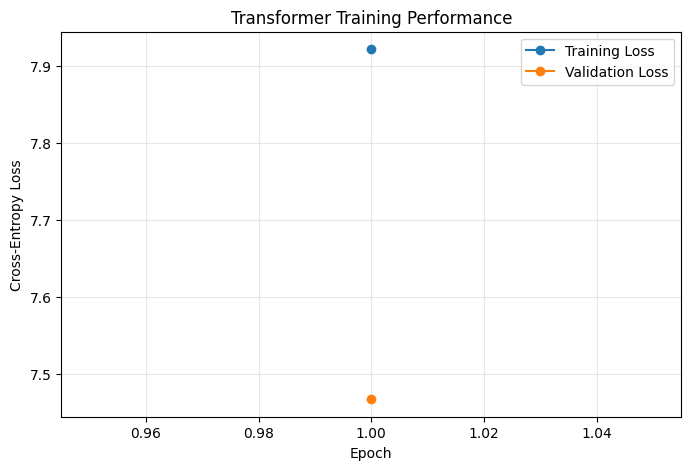

In [43]:
plt.figure(figsize=(8, 5))

epochs = range(1, len(history["train_loss"]) + 1)

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Transformer Training Performance")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Check GPU Memory Usage

In [44]:
if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated() / 1024**3

    peak = torch.cuda.max_memory_allocated() / 1024**3

    total = torch.cuda.get_device_properties(0).total_memory / 1024**3

    print(f"Current Allocated: {allocated:.2f} GB")
    print(f"Peak Allocated: {peak:.2f} GB")
    print(f"Total GPU Memory: {total:.2f} GB")

Current Allocated: 0.28 GB
Peak Allocated: 0.70 GB
Total GPU Memory: 14.56 GB


# Full Dataset Training

## Configure Full Training

In [45]:
FULL_EPOCHS = 20
EARLY_STOP_PATIENCE = 3
LEARNING_RATE = 3e-4

# Fresh model
model = TransformerSummarizer().to(device)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Training Samples:", len(train_dataset))
print("Validation Samples:", len(val_dataset))
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Maximum Epochs:", FULL_EPOCHS)

Training Samples: 30000
Validation Samples: 2000
Training Batches: 3750
Validation Batches: 250
Maximum Epochs: 20


## Train with Early Stopping & Checkpointing

In [46]:
import os
import time

# Stable training configuration
USE_AMP = False
LEARNING_RATE = 1e-4

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=False
)

# Avoid multiprocessing cleanup errors
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

# Training configuration
FULL_EPOCHS = 20
EARLY_STOP_PATIENCE = 3

history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
bad_epochs = 0

BEST_PATH = "/kaggle/working/best_transformer.pth"
LAST_PATH = "/kaggle/working/last_transformer.pth"

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

# Full training
for epoch in range(1, FULL_EPOCHS + 1):

    start_time = time.time()

    try:
        train_loss = run_epoch(
            train_loader,
            training=True
        )

        val_loss = run_epoch(
            val_loader,
            training=False
        )

    except FloatingPointError as e:
        print(f"\nNumerical error at Epoch {epoch}: {e}")
        print("Stopping training safely.")

        if os.path.exists(BEST_PATH):
            saved = torch.load(
                BEST_PATH,
                map_location=device,
                weights_only=True
            )

            model.load_state_dict(
                saved["model_state_dict"]
            )

            print("Best valid checkpoint restored.")
        else:
            print("No valid checkpoint was created.")
            raise

        break

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    elapsed = (time.time() - start_time) / 60

    improved = val_loss < best_val_loss - 1e-4

    if improved:
        best_val_loss = val_loss
        bad_epochs = 0
    else:
        bad_epochs += 1

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "bad_epochs": bad_epochs,
        "history": history
    }

    torch.save(checkpoint, LAST_PATH)

    if improved:
        torch.save(checkpoint, BEST_PATH)
        print("Best model updated!")

    print(f"\nEpoch {epoch}/{FULL_EPOCHS}")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Best Validation Loss: {best_val_loss:.4f}")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")
    print(f"Time: {elapsed:.2f} minutes")

    if bad_epochs >= EARLY_STOP_PATIENCE:
        print("\nEarly stopping triggered!")
        break

print("\nFull Training Completed!")
print("Epochs Completed:", len(history["train_loss"]))
print(f"Best Validation Loss: {best_val_loss:.4f}")

Training:   0%|          | 0/3750 [00:00<?, ?it/s]

Validation:   0%|          | 0/250 [00:00<?, ?it/s]

Best model updated!

Epoch 1/20
Training Loss: 6.9590
Validation Loss: 6.3889
Best Validation Loss: 6.3889
Learning Rate: 0.000100
Time: 4.53 minutes


Training:   0%|          | 0/3750 [00:00<?, ?it/s]

Validation:   0%|          | 0/250 [00:00<?, ?it/s]

Best model updated!

Epoch 2/20
Training Loss: 6.2739
Validation Loss: 5.9648
Best Validation Loss: 5.9648
Learning Rate: 0.000100
Time: 4.61 minutes


... (50 outputs left out)

Best model updated!

Epoch 19/20
Training Loss: 4.5381
Validation Loss: 5.0712
Best Validation Loss: 5.0712
Learning Rate: 0.000100
Time: 4.58 minutes


Training:   0%|          | 0/3750 [00:00<?, ?it/s]

Validation:   0%|          | 0/250 [00:00<?, ?it/s]

Best model updated!

Epoch 20/20
Training Loss: 4.5018
Validation Loss: 5.0620
Best Validation Loss: 5.0620
Learning Rate: 0.000100
Time: 4.58 minutes

Full Training Completed!
Epochs Completed: 20
Best Validation Loss: 5.0620


## Visualize Full Training Performance

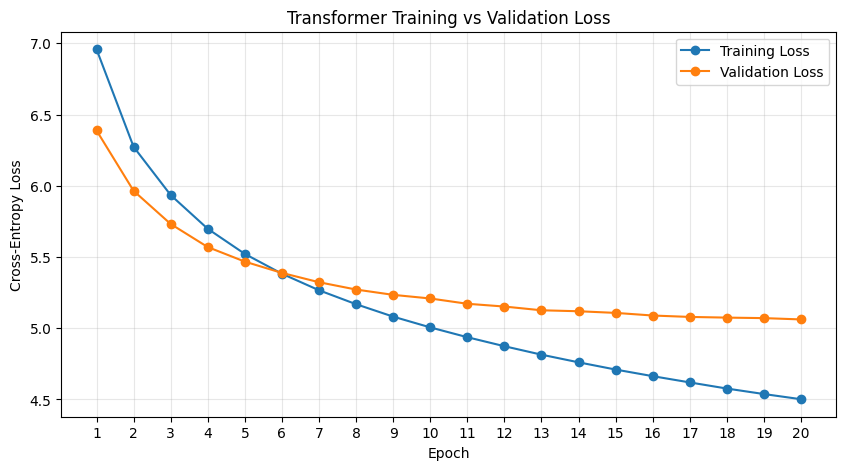

In [47]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Transformer Training vs Validation Loss")

plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Load the Best Model

In [48]:
checkpoint = torch.load(
    BEST_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best Epoch:", checkpoint["epoch"])
print("Best Validation Loss:",
      checkpoint["best_val_loss"])

print("Best model loaded successfully!")

Best Epoch: 20
Best Validation Loss: 5.062006387328117
Best model loaded successfully!


## Check GPU Memory

In [49]:
if torch.cuda.is_available():

    peak = torch.cuda.max_memory_allocated() / 1024**3
    reserved = torch.cuda.max_memory_reserved() / 1024**3
    total = torch.cuda.get_device_properties(0).total_memory / 1024**3

    print(f"Peak Allocated: {peak:.2f} GB")
    print(f"Peak Reserved: {reserved:.2f} GB")
    print(f"Total GPU Memory: {total:.2f} GB")

Peak Allocated: 0.85 GB
Peak Reserved: 1.18 GB
Total GPU Memory: 14.56 GB


# Abstractive Summarization Inference

## Implement Greedy Decoding

In [50]:
@torch.inference_mode()
def generate_summary(article, max_new_tokens=127):

    model.eval()

    # Encode source article
    src = torch.tensor(
        [encode_article(article)],
        dtype=torch.long,
        device=device
    )

    src_mask = (src == PAD_ID)

    # Run encoder once
    src_emb = model.src_position(
        model.src_embedding(src)
    )

    memory = model.encoder(src_emb, src_mask)

    # Start decoder with BOS
    generated = torch.tensor(
        [[BOS_ID]],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):

        tgt_len = generated.size(1)

        tgt_mask = (generated == PAD_ID)

        causal_mask = torch.triu(
            torch.ones(
                tgt_len,
                tgt_len,
                dtype=torch.bool,
                device=device
            ),
            diagonal=1
        )

        # Decoder embeddings
        tgt_emb = model.tgt_position(
            model.tgt_embedding(generated)
        )

        # Decoder forward pass
        decoder_output = model.decoder(
            tgt_emb,
            memory,
            src_mask,
            tgt_mask,
            causal_mask
        )

        # Predict the next token
        logits = model.fc_out(
            decoder_output[:, -1, :]
        )

        next_token = logits.argmax(
            dim=-1, keepdim=True
        )

        generated = torch.cat(
            [generated, next_token],
            dim=1
        )

        if next_token.item() == EOS_ID:
            break

    # Convert generated IDs into text
    token_ids = generated.squeeze(0).tolist()

    summary = tokenizer.decode(
        token_ids,
        skip_special_tokens=True
    )

    return summary.strip()

## Generate First Summary

In [51]:
sample = val_data.iloc[0]

article = sample["article"]
reference = sample["highlights"]

generated = generate_summary(article)

print("=" * 60)
print("ORIGINAL ARTICLE:")
print(article[:1200])

print("\n" + "=" * 60)
print("REFERENCE SUMMARY:")
print(reference)

print("\n" + "=" * 60)
print("GENERATED SUMMARY:")
print(generated)

ORIGINAL ARTICLE:
A bird that was long thought to have gone extinct has been rediscovered in Burma after a team of scientists used a recording of the species' distinctive call to track it down. The Jerdon's Babbler (chrysomma altirostre altirostre) - a small brown bird similar in size to a house sparrow - was last spotted in Myanmar in 1941 and was thought to have died out altogether. But a team of scientists managed to uncover multiple birds nesting in a small area of grassland in Myanmar's central Bago region in May last year, according to their report published in the latest edition of Birding Asia. Re-discovered: The Jerdon's Babbler which was thought extinct for 73 years until scientists found evidence of it living in Burma . The scientists targeted some of the few remaining patches of wild grassland left along Myanmar's mighty Irrawaddy river, now one of the most heavily cultivated and densely populated regions of the impoverished but emerging southeast Asian nation. At one small

## Test Multiple Articles

In [52]:
samples = val_data.sample(
    n=3,
    random_state=SEED
)

for i, (_, row) in enumerate(samples.iterrows(), 1):

    generated = generate_summary(row["article"])

    print(f"\n{'='*25} SAMPLE {i} {'='*25}")

    print("\nARTICLE PREVIEW:")
    print(row["article"][:500])

    print("\nREFERENCE SUMMARY:")
    print(row["highlights"])

    print("\nGENERATED SUMMARY:")
    print(generated)



========================= SAMPLE 1 =========================

ARTICLE PREVIEW:
(CNN)A 17-year-old male fatally shot an Iraqi man watching his first snowfall in his new American hometown, targeting him and then continuing to fire as the immigrant rushed to get inside, Dallas police said Friday. Authorities don't believe the suspected shooter knew the victim, Ahmed Al-Jumaili, Dallas Police Maj. Jeff Cotner said reporters, nor do they believe he knew Al-Jumaili's ethnicity. And they haven't given any indication Al-Jumaili had anything to do with what led the teen to head out

REFERENCE SUMMARY:
Ahmed Al-Jumaili, who'd come from Iraq weeks earlier, was shot while outside watching snow . Police: Suspected shooter went out angry thinking someone shot his girlfriend's apartment . There's no indication Al-Jumaili had anything to do with that or knew the suspected shooter .

GENERATED SUMMARY:
NEW: Suspect's family says he's "I don't be a man" Police say they are in the suspect's family says 

## Check Generated Summary Length

In [53]:
sample = val_data.iloc[0]

generated = generate_summary(sample["article"])

print("Reference Words:",
      len(sample["highlights"].split()))

print("Generated Words:",
      len(generated.split()))

print("Generated Tokens:",
      len(tokenizer.encode(
          generated,
          add_special_tokens=False
      ).ids))

Reference Words: 37
Generated Words: 125
Generated Tokens: 127


# Inference Results Analysis

## Repetition-Controlled Greedy Decoding

In [54]:
@torch.inference_mode()
def generate_summary_v2(
    article,
    max_new_tokens=127,
    min_new_tokens=15,
    repetition_penalty=1.2,
    no_repeat_ngram_size=3
):
    model.eval()

    src = torch.tensor(
        [encode_article(article)],
        dtype=torch.long,
        device=device
    )

    src_mask = (src == PAD_ID)

    src_emb = model.src_position(
        model.src_embedding(src)
    )

    memory = model.encoder(src_emb, src_mask)

    generated = torch.tensor(
        [[BOS_ID]],
        dtype=torch.long,
        device=device
    )

    max_new_tokens = min(
        max_new_tokens,
        MAX_SUMMARY_LEN - 1
    )

    for step in range(max_new_tokens):

        tgt_len = generated.size(1)

        tgt_mask = (generated == PAD_ID)

        causal_mask = torch.triu(
            torch.ones(
                tgt_len, tgt_len,
                dtype=torch.bool,
                device=device
            ),
            diagonal=1
        )

        tgt_emb = model.tgt_position(
            model.tgt_embedding(generated)
        )

        decoder_output = model.decoder(
            tgt_emb,
            memory,
            src_mask,
            tgt_mask,
            causal_mask
        )

        logits = model.fc_out(
            decoder_output[:, -1, :]
        ).clone()

        # Block invalid generation tokens
        logits[:, [PAD_ID, UNK_ID, BOS_ID]] = float("-inf")

        # Require a minimum summary length
        if step < min_new_tokens:
            logits[:, EOS_ID] = float("-inf")

        # Repetition penalty
        previous_ids = generated[0].unique()

        scores = logits[0, previous_ids]

        logits[0, previous_ids] = torch.where(
            scores < 0,
            scores * repetition_penalty,
            scores / repetition_penalty
        )

        # Prevent repeated token n-grams
        ids = generated[0].tolist()
        n = no_repeat_ngram_size

        if n > 1 and len(ids) >= n - 1:
            prefix = ids[-(n - 1):]

            for i in range(len(ids) - n + 1):
                if ids[i:i + n - 1] == prefix:
                    blocked_id = ids[i + n - 1]
                    logits[0, blocked_id] = float("-inf")

        if not torch.isfinite(logits).any():
            break

        next_token = logits.argmax(
            dim=-1,
            keepdim=True
        )

        if next_token.item() == EOS_ID:
            break

        generated = torch.cat(
            [generated, next_token],
            dim=1
        )

    return tokenizer.decode(
        generated[0].tolist(),
        skip_special_tokens=True
    ).strip()

## Compare Original vs Improved Decoding

In [55]:
samples = val_data.sample(
    n=3,
    random_state=SEED
)

for i, (_, row) in enumerate(samples.iterrows(), 1):

    original = generate_summary(row["article"])

    improved = generate_summary_v2(row["article"])

    print(f"\n{'='*25} SAMPLE {i} {'='*25}")

    print("\nREFERENCE SUMMARY:")
    print(row["highlights"])

    print("\nORIGINAL GREEDY SUMMARY:")
    print(original)

    print("\nREPETITION-CONTROLLED SUMMARY:")
    print(improved)


========================= SAMPLE 1 =========================

REFERENCE SUMMARY:
Ahmed Al-Jumaili, who'd come from Iraq weeks earlier, was shot while outside watching snow . Police: Suspected shooter went out angry thinking someone shot his girlfriend's apartment . There's no indication Al-Jumaili had anything to do with that or knew the suspected shooter .

ORIGINAL GREEDY SUMMARY:
NEW: Suspect's family says he's "I don't be a man" Police say they are in the suspect's family says he's a "si-defense" He was shot dead . The suspect's a "I have been charged with a gun control of the first-degree murder .

REPETITION-CONTROLLED SUMMARY:
NEW: Suspect's family says he was shot dead . NEW: "We are not a gun control" Police say the suspect in his own life-year-old man, police say .

========================= SAMPLE 2 =========================

REFERENCE SUMMARY:
Roy Hodgson's interview alongside Paul McGinley would surely have FA bosses thinking Euro 2016 should be his last tournament as coa

## Inspect Article Truncation

In [56]:
lengths = np.array(article_lengths)

limit = MAX_ARTICLE_LEN - 2

truncated_percentage = (
    np.mean(lengths > limit) * 100
)

retained_percentage = np.mean(
    np.minimum(lengths, limit) /
    np.maximum(lengths, 1)
) * 100

print(
    f"Articles Truncated: {truncated_percentage:.2f}%"
)

print(
    f"Average Source Tokens Retained: "
    f"{retained_percentage:.2f}%"
)

Articles Truncated: 80.30%
Average Source Tokens Retained: 65.53%


# ROUGE Evaluation

## Install & Import ROUGE

In [57]:
!pip -q install rouge-score

In [58]:
from rouge_score import rouge_scorer
from tqdm.auto import tqdm

rouge = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

def calculate_rouge(reference, prediction):
    scores = rouge.score(reference, prediction)

    return {
        metric: scores[metric].fmeasure
        for metric in ["rouge1", "rouge2", "rougeL"]
    }

## Implement Lead-3 Baseline

In [59]:
import re

def lead3_summary(article):
    sentences = re.split(
        r"(?<=[.!?])\s+",
        article.strip()
    )

    return " ".join(sentences[:3])

sample = val_data.iloc[0]

print("Lead-3 Summary:")
print(lead3_summary(sample["article"]))

Lead-3 Summary:
A bird that was long thought to have gone extinct has been rediscovered in Burma after a team of scientists used a recording of the species' distinctive call to track it down. The Jerdon's Babbler (chrysomma altirostre altirostre) - a small brown bird similar in size to a house sparrow - was last spotted in Myanmar in 1941 and was thought to have died out altogether. But a team of scientists managed to uncover multiple birds nesting in a small area of grassland in Myanmar's central Bago region in May last year, according to their report published in the latest edition of Birding Asia.


## Generate Summaries for Evaluation

In [60]:
EVAL_SAMPLES = 30

eval_df = val_data.sample(
    n=min(EVAL_SAMPLES, len(val_data)),
    random_state=SEED
).reset_index(drop=True)

results = []

for _, row in tqdm(
    eval_df.iterrows(),
    total=len(eval_df),
    desc="Generating Summaries"
):
    article = row["article"]

    results.append({
        "reference": row["highlights"],
        "greedy": generate_summary(article),
        "improved": generate_summary_v2(article),
        "lead3": lead3_summary(article)
    })

results_df = pd.DataFrame(results)

print("Evaluated Samples:", len(results_df))
display(results_df.head())

Generating Summaries:   0%|          | 0/30 [00:00<?, ?it/s]

Evaluated Samples: 30


,reference,greedy,improved,lead3
0,"Ahmed Al-Jumaili, who'd come from Iraq weeks e...","NEW: Suspect's family says he's ""I don't be a ...",NEW: Suspect's family says he was shot dead . ...,(CNN)A 17-year-old male fatally shot an Iraqi ...
1,Roy Hodgson's interview alongside Paul McGinle...,David Beckham has been appointed since the Yea...,David Beckham has been appointed since the Yea...,England football coach Roy Hodgson was the tal...
2,Tony Abbott has pleaded with Labor to back a n...,The Australian Prime Minister Tony Abbott said...,The Australian Prime Minister Tony Abbott said...,Tony Abbott has pleaded with Labor to back leg...
3,The moment of misfortune occurred when the cut...,The whale was spotted by a hole in the water ....,The whale was spotted by a hole in the water ....,We all have those days when nothing seems to g...
4,Greek government has insisted that Germany mus...,Survey says he is 'devil' to be 'devil' to be ...,Survey says he is 'devil' to be held in the EU...,The Greek foreign minister has claimed that hi...


## Calculate ROUGE Scores

In [61]:
methods = {
    "Greedy": "greedy",
    "Repetition Controlled": "improved",
    "Lead-3 Baseline": "lead3"
}

evaluation_results = []

for method_name, column in methods.items():

    scores = [
        calculate_rouge(ref, pred)
        for ref, pred in zip(
            results_df["reference"],
            results_df[column]
        )
    ]

    avg_scores = {
        metric: np.mean([
            score[metric] for score in scores
        ]) * 100
        for metric in ["rouge1", "rouge2", "rougeL"]
    }

    evaluation_results.append({
        "Method": method_name,
        **avg_scores
    })

rouge_df = pd.DataFrame(
    evaluation_results
).set_index("Method")

display(rouge_df.round(2))

,rouge1,rouge2,rougeL
Method,,,
Greedy,17.24,2.60,12.91
Repetition Controlled,23.98,3.91,14.54
Lead-3 Baseline,40.94,17.20,25.37


## Visualize ROUGE Comparison

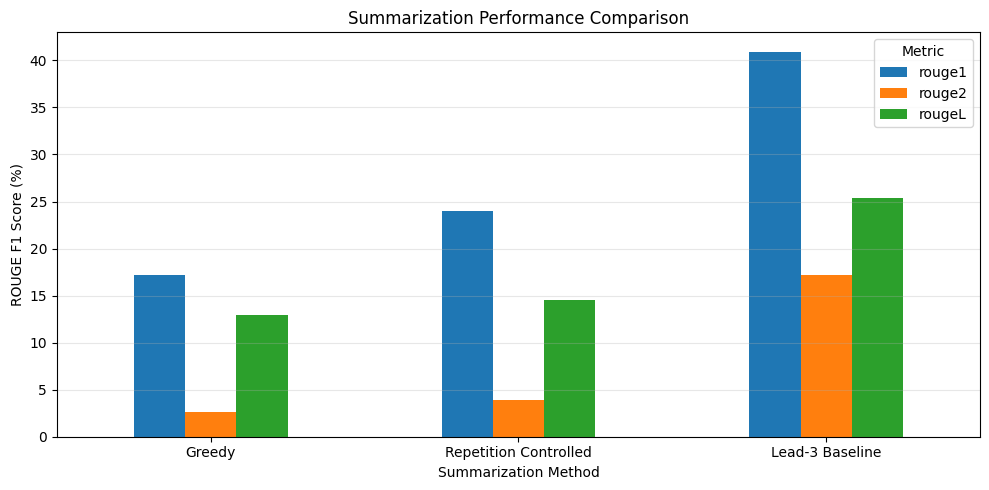

In [62]:
ax = rouge_df.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Summarization Performance Comparison")
plt.xlabel("Summarization Method")
plt.ylabel("ROUGE F1 Score (%)")
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Save Evaluation Results

In [63]:
results_df.to_csv(
    "/kaggle/working/summary_predictions.csv",
    index=False
)

rouge_df.to_csv(
    "/kaggle/working/rouge_results.csv"
)

print("Evaluation results saved!")

Evaluation results saved!
